In [1]:
import seaborn as sns

sns.set_theme(
    context="paper", style="ticks", rc={"axes.spines.top": False, "axes.spines.right": False}
)

# **`scipy` : librairie pour la programmation scientifique**

- Le module `scipy` vise à unifier et fédérer un ensemble de bibliothèques Python à usage scientifique

- `scipy` s'appuie sur `numpy` en utilisant les objets de type tableaux et fournit des algorithmes scientifiques optimisés :
  - Algèbre linéaire (résolution d'équations linéaires, valeurs/vecteur propres)
  - Fonctions spéciales (fonction de Bessel, loi de distribution,...)
  - Algorithmes d'interpolation, d'intégration et d'**optimisation**
  - **Résolution d'équations différentielles ordinaires**
  - Traitement du signal et des images (transformée de Fourier, convolution,...)

## **Installation & importation de `scipy`**

- Installation *via* `pip`
  ```sh
  pip install scipy
  ```
- Convention d'importation : étant donné la grande variété de problèmes auxquels répond `scipy`, les modules sont importés individuellement. Ainsi, pour importer les algorithmes ayant trait à l'algèbre linéaire, on utilisera

In [2]:
from scipy import linalg

## **`scipy.linalg` : algèbre linéaire**

- Le module `scipy.linalg` inclut diverses fonctions dont
  - les opérations matricielles (inversion de matrices, calcul de déterminant)
  - résolution d'équations linéaires $Ax=b$
  - recherche de valeurs/vecteurs propres
  - pivot de Gauss, décomposition en valeurs singulières, ...

In [3]:
import numpy as np
from scipy import linalg

A = np.random.rand(2, 2)
A

array([[0.91668708, 0.6370342 ],
       [0.74173549, 0.44420558]])

Pour calculer le déterminant de la matrice $A$

In [4]:
linalg.det(A)

np.float64(-0.06531335750514787)

et on utilisera `linalg.inv` pour déterminer la matrice inverse

In [5]:
linalg.inv(A) * linalg.det(A)

array([[ 0.44420558, -0.6370342 ],
       [-0.74173549,  0.91668708]])

Pour résoudre un système d'équations linéaires $Ax = b$, on utilisera la fonction `linalg.solve`

In [6]:
A = np.random.rand(3, 3)
b = np.random.rand(3)

x = linalg.solve(A, b)
x

array([ 1.19296768, -0.73580026,  0.72354961])

In [7]:
A @ x - b

array([0.00000000e+00, 0.00000000e+00, 5.55111512e-17])

Pour rechercher les valeurs/vecteurs propres $Av_n=\lambda_nv_n$ où $v_n$ est le $n^\text{ième}$ vecteur propre et $\lambda_n$ la $n^\text{ième}$ valeur propre, on se servira de la fonction `linalg.eig` de la façon suivante

In [8]:
evals, evecs = linalg.eig(A)

evals

array([1.50614516+0.j        , 0.2307152 +0.26244947j,
       0.2307152 -0.26244947j])

In [9]:
evecs

array([[ 0.41198116+0.j        , -0.70699648+0.j        ,
        -0.70699648-0.j        ],
       [ 0.60513394+0.j        ,  0.36298902+0.36452889j,
         0.36298902-0.36452889j],
       [ 0.68123743+0.j        ,  0.26654873-0.40554335j,
         0.26654873+0.40554335j]])

In [10]:
n = 1
linalg.norm(A @ evecs[:, n] - evals[n] * evecs[:, n])

2.246115240728562e-16

## **`scipy.special` : fonctions spéciales**

- Fonctions de Bessel :
  $x^2\frac{\text{d}^2y}{\text{d}x^2}+x\frac{\text{d}y}{\text{d}x}+(x^2-\alpha^2)y=0$

  - Fonctions de Bessel de première espèce $J_n$
  - Fonctions de Bessel de seconde espèce $Y_n$

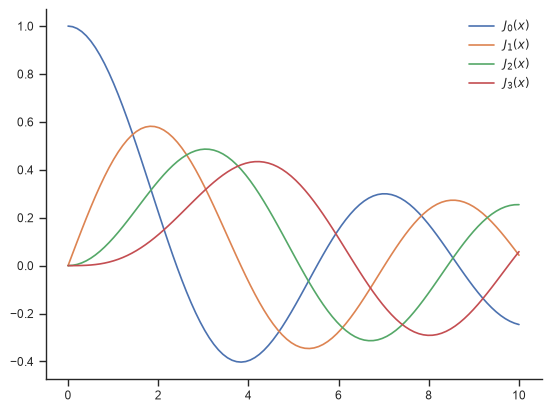

In [11]:
import matplotlib.pyplot as plt
from scipy.special import jn, yn

x = np.linspace(0, 10, 100)
for n in range(4):
    plt.plot(x, jn(n, x), label=f"$J_{n}(x)$")
plt.legend();

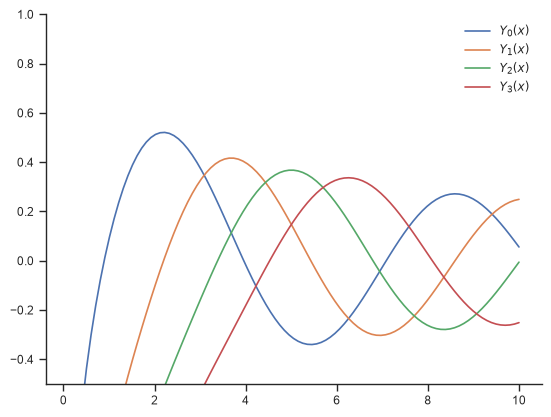

In [12]:
for n in range(4):
    plt.plot(x, yn(n, x), label=f"$Y_{n}(x)$")
plt.ylim(-0.5, 1)
plt.legend();

Pour découvrir l'ensemble des [fonctions spéciales](https://docs.scipy.org/doc/scipy/reference/special.html) offertes par `scipy`

In [13]:
from scipy import special
special?

Type:        module
String form: <module 'scipy.special' from '/home/garrido/.local/lib/python3.14/site-packages/scipy/special/__init__.py'>
File:        ~/.local/lib/python3.14/site-packages/scipy/special/__init__.py
Docstring:  
Special functions (:mod:`scipy.special`)

.. currentmodule:: scipy.special

.. toctree::
   :hidden:

   special.cython_special

Almost all of the functions below accept NumPy arrays as input
arguments as well as single numbers. This means they follow
broadcasting and automatic array-looping rules. Technically,
they are `NumPy universal functions
<https://numpy.org/doc/stable/user/basics.ufuncs.html#ufuncs-basics>`_.
Functions which do not accept NumPy arrays are marked by a warning
in the section description.

.. seealso::

   `scipy.special.cython_special` -- Typed Cython versions of special functions


Error handling

Errors are handled by returning NaNs or other appropriate values.
Some of the special function routines can emit warnings or raise
exception

## **`scipy.interpolate` : interpolation numérique**

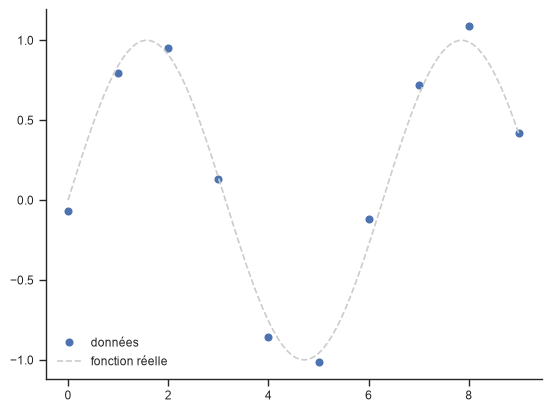

In [14]:
def f(x):
    return np.sin(x)


x_meas = np.arange(0, 10)
y_meas = f(x_meas) + 0.1 * np.random.randn(x_meas.size)

fig, ax = plt.subplots()
ax.plot(x_meas, y_meas, "o", label="données")
ax.plot(x := np.linspace(0, 9, 100), f(x), label="fonction réelle", c="0.8", ls="dashed")
ax.legend();

Si à partir des 10 points expérimentaux, on souhaite interpoler linéairement entre chaque couple $(x_\text{meas}, y_\text{meas})$, on peut utiliser la fonction `interp1d` du module `scipy.interpolate`. Numériquement, `scipy` calcule les coefficients des fonctions linéaires $(a, b)$ entre chaque point : l'objet `linear_interpolation` ci-dessous est une fonction prenant en argument un vecteur de valeurs $x$ et retournant les valeurs de $y$ associées à chaque segment d'interpolation

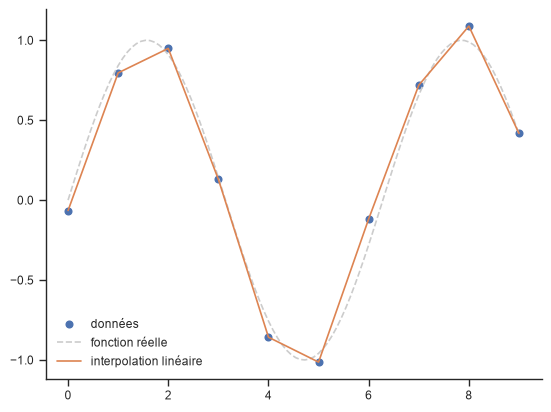

In [15]:
from scipy.interpolate import interp1d

linear_interpolation = interp1d(x_meas, y_meas)

ax.plot(x, linear_interpolation(x), label="interpolation linéaire")
ax.legend()
fig

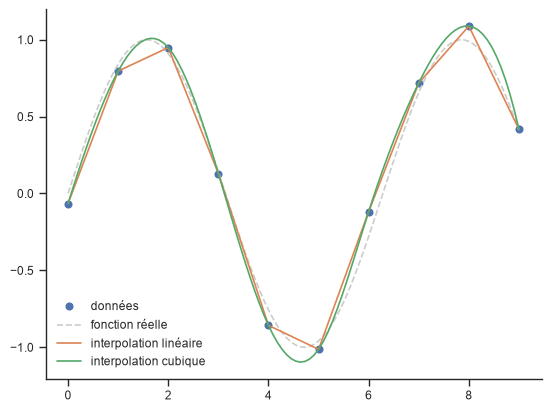

In [16]:
cubic_interpolation = interp1d(x_meas, y_meas, kind="cubic")

ax.plot(x, cubic_interpolation(x), label="interpolation cubique")
ax.legend()
fig

## **`scipy.integrate` : intégration de fonctions**

L'intégration numérique de $\int_a^bf(x)\text{d}x$ peut se faire *via* le module `scipy.integrate` :
  - **`quad`** calcule une intégrale simple
  - **`dblquad`** calcule une intégrale double
  - **`tplquad`** calcule une intégrale triple
  - **`nquad`** calcule une intégrale à $n$ dimensions

- Exemple $\int_{-\infty}^{+\infty}\exp(-x^2)\text{d}x = \sqrt\pi$

In [17]:
from scipy.integrate import quad

val, abserr = quad(lambda x: np.exp(-x**2), -np.inf, +np.inf)
print(f"I = {val} +/- {abserr}")

I = 1.7724538509055159 +/- 1.4202636780944923e-08


- Exemple d'intégration avec passage de paramètre : $I(a,b)=\int_{0}^{1}(ax^2+b)\text{d}x$

In [18]:
from scipy.integrate import quad


def integrand(x, a, b):
    return a * x**2 + b


a = 2
b = 1
quad(integrand, 0, 1, args=(a, b))

(1.6666666666666667, 1.8503717077085944e-14)

- Exemple d'intégrale multiple
    \begin{align*}
      I_n=\int_{x=0}^\infty\int_{t=1}^\infty\frac{e^{-xt}}{t^n}\text{d}t\text{d}x=\frac{1}{n}
    \end{align*}


In [19]:
def I(n):
    from scipy.integrate import nquad

    return nquad(lambda t, x: np.exp(-x * t) / t**n, [[1, np.inf], [0, np.inf]])


I(4)[0], I(4)[0] - 1 / 4

(0.2500000000043577, 4.357680882804971e-12)

In [20]:
I(100)[0], I(100)[0] - 1 / 100

(0.010000000000118046, 1.1804619781674575e-13)

## **`scipy.integrate`: résolution d'équations différentielles ordinaires**

- `scipy` fournit l'interface **`solve_ivp`** (*Solve an Initial Value Problem*) pour résoudre les EDO

- Une équation différentielle ordinaire peut s'écrire sous la forme **$y'=f(y, t)$** où **$y = [y_1(t), y_2(t),\ldots, y_n(t)]$** et **$f$ est une fonction fournissant les dérivées des fonctions $y_i(t)$**

- La résolution *via* la fonction `solve_ivp` implique la connaissance de $f$ et des conditions initiales $y(0)$

  ```python
    y_t = solve_ivp(f, t, y0)
  ```

  où `t` est un vecteur `numpy` correspondant à l'échantillonnage (temps, position,...) et `y_t` contient, pour chaque échantillon `t`, une colonne pour chaque solution $y_i(t)$

### **Exemple : [Mouvement du double pendule](http://en.wikipedia.org/wiki/Double_pendulum)**

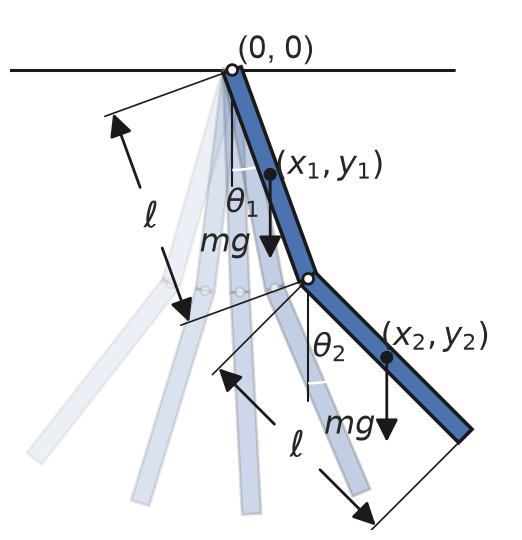

In [21]:
%run figures/dbl_pendulum.py

  \begin{align*}
    \dot{\theta}_1&=\frac{6}{m\ell^2}\times\frac{2p_{\theta_1}-3\cos(\theta_1-\theta_2)p_{\theta_2}}{16-9\cos^2(\theta_1-\theta_2)}\\
    \dot{\theta}_2&=\frac{6}{m\ell^2}\times\frac{8p_{\theta_2}-3\cos(\theta_1-\theta_2)p_{\theta_1}}{16-9\cos^2(\theta_1-\theta_2)}\\
    \dot{p}_{\theta_1}&=-\frac{1}{2}m\ell^2\left[\dot{\theta}_1\dot{\theta}_2\sin(\theta_1-\theta_2)+3\frac{g}{\ell}\sin\theta_1\right]\\
    \dot{p}_{\theta_2}&=-\frac{1}{2}m\ell^2\left[-\dot{\theta}_1\dot{\theta}_2\sin(\theta_1-\theta_2)+\frac{g}{\ell}\sin\theta_2\right]
  \end{align*}

où $p_{\theta_i}$ sont les impulsions des barycentres $(x_1, y_1)$ et $(x_2,
y_2)$.

On pose $y=[\theta_1,\theta_2,p_{\theta_1},p_{\theta_2}]$

  \begin{align*}
    \dot{y}_0&=\frac{6}{m\ell^2}\times\frac{2y_2-3\cos(y_0-y_1)y_3}{16-9\cos^2(y_0-y_1)}\\
    \dot{y}_1&=\frac{6}{m\ell^2}\times\frac{8y_3-3\cos(y_0-y_1)y_2}{16-9\cos^2(y_0-y_1)}\\
    \dot{y}_2&=-\frac{1}{2}m\ell^2\left[\dot{y}_0\dot{y}_1\sin(y_0-y_1)+3\frac{g}{\ell}\sin y_0\right]\\
    \dot{y}_3&=-\frac{1}{2}m\ell^2\left[-\dot{y}_0\dot{y}_1\sin(y_0-y_1)+\frac{g}{\ell}\sin y_1\right]\\
  \end{align*}


In [22]:
g, ℓ, m = 9.82, 0.5, 0.1


def dy(t, y):
    θ1, θ2, p1, p2 = y[0], y[1], y[2], y[3]

    dθ1 = 6.0 / m / ℓ**2 * (2 * p1 - 3 * np.cos(θ1 - θ2) * p2) / (16 - 9 * np.cos(θ1 - θ2) ** 2)
    dθ2 = 6.0 / m / ℓ**2 * (8 * p2 - 3 * np.cos(θ1 - θ2) * p1) / (16 - 9 * np.cos(θ1 - θ2) ** 2)
    dp1 = -0.5 * m * ℓ**2 * (+dθ1 * dθ2 * np.sin(θ1 - θ2) + 3 * g / ℓ * np.sin(θ1))
    dp2 = -0.5 * m * ℓ**2 * (-dθ1 * dθ2 * np.sin(θ1 - θ2) + 1 * g / ℓ * np.sin(θ2))

    return dθ1, dθ2, dp1, dp2

En choisissant comme conditions initiales $\theta_1=\tfrac{\pi}{4}, \theta_2=\tfrac{\pi}{2}$ et des pendules au repos *i.e.* $p_1=p_2=0$, on résout l'équation différentielle dans l'intervalle de temps $t\in[0, 10]$ secondes à l'aide de la fonction `solve_ivp`

In [23]:
# Conditions initiales
y0 = [np.pi / 4, np.pi / 2, 0, 0]

# Échantillonnage du temps
t = np.linspace(0, 10, 250)

# Résolution des équations différentielles
from scipy.integrate import solve_ivp

sol = solve_ivp(dy, t_span=[0, 10], y0=y0, t_eval=t)
sol

  message: The solver successfully reached the end of the integration interval.
  success: True
   status: 0
        t: [ 0.000e+00  4.016e-02 ...  9.960e+00  1.000e+01]
        y: [[ 7.854e-01  7.767e-01 ... -6.695e-02  1.021e-01]
            [ 1.571e+00  1.556e+00 ... -4.811e-01 -3.800e-01]
            [ 0.000e+00 -2.083e-02 ...  1.694e-01  1.665e-01]
            [ 0.000e+00 -9.889e-03 ...  6.504e-02  7.154e-02]]
      sol: None
 t_events: None
 y_events: None
     nfev: 812
     njev: 0
      nlu: 0

L'objet `sol` contient un certain nombre d'informations liées à la résolution du système dont l'échantillon en temps `t` ainsi qu'un tableau `y` contenant les valeurs de $y$ à chaque install $t$. On peut alors représenter graphiquement la variation de $\theta_{1,2}$ en fonction du temps ou la position des barycentres $(x_{1,2}, y_{1,2})$

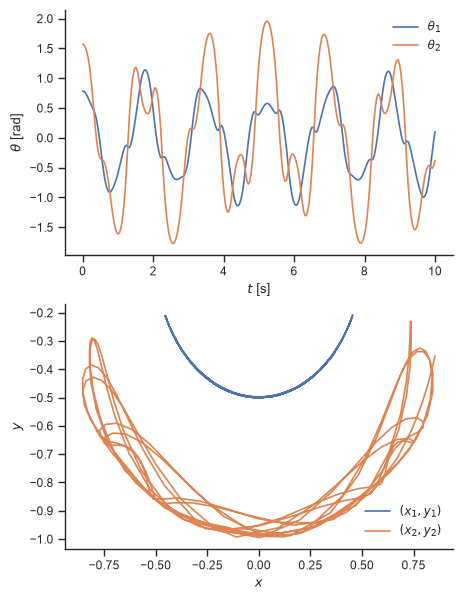

In [24]:
θ1, θ2 = sol.y[0], sol.y[1]
fig, ax = plt.subplots(2, 1, figsize=(5, 7))
ax[0].plot(t, θ1, label=r"$\theta_1$")
ax[0].plot(t, θ2, label=r"$\theta_2$")
ax[0].set(xlabel=r"$t$ [s]", ylabel=r"$\theta$ [rad]")
ax[0].legend()

x1 = +ℓ * np.sin(θ1)
y1 = -ℓ * np.cos(θ1)
x2 = x1 + ℓ * np.sin(θ2)
y2 = y1 - ℓ * np.cos(θ2)
ax[1].plot(x1, y1, label=r"$(x_1, y_1)$")
ax[1].plot(x2, y2, label=r"$(x_2, y_2)$")
ax[1].set(xlabel=r"$x$", ylabel=r"$y$")
ax[1].legend();

In [25]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

# This is needed to disable plotting the static figure in jupyter notebook
with plt.ioff():
    fig = plt.figure()
    ax = fig.add_subplot(111, autoscale_on=False, xlim=(-1, 1), ylim=(-1.2, 0.2))
    ax.grid()

    (pendule,) = ax.plot([], [], "ok-", lw=2)
    (mvt1,) = ax.plot([], [], c="C0")
    (mvt2,) = ax.plot([], [], c="C1")
    text = ax.text(0.05, 0.9, "", transform=ax.transAxes)

    def animate(i):
        thisx = [0, x1[i], x2[i]]
        thisy = [0, y1[i], y2[i]]

        pendule.set_data(thisx, thisy)
        mvt1.set_data(x1[:i], y1[:i])
        mvt2.set_data(x2[:i], y2[:i])
        text.set_text(f"temps = {i * 0.04:.1f} s")
        return pendule, mvt1, mvt2, text

    ani = FuncAnimation(fig, animate, np.arange(1, len(t)), interval=25, blit=True)
    display(HTML(ani.to_jshtml()))

### **Exemple : Oscillateur harmonique amorti**

  \begin{align*}
    \frac{\text{d}^2x}{\text{d}t^2}+2\zeta\omega_0\frac{\text{d}x}{\text{d}t}+\omega_0^2x=0
  \end{align*}

On pose $p = \frac{\text{d}x}{\text{d}t}$
    \begin{equation*}
      \left\{\begin{aligned}
      \frac{\text{d}p}{\text{d}t}&=-2\zeta\omega_0p-\omega_0^2x\\
      \frac{\text{d}x}{\text{d}t}&=p
      \end{aligned}\right.
    \end{equation*}

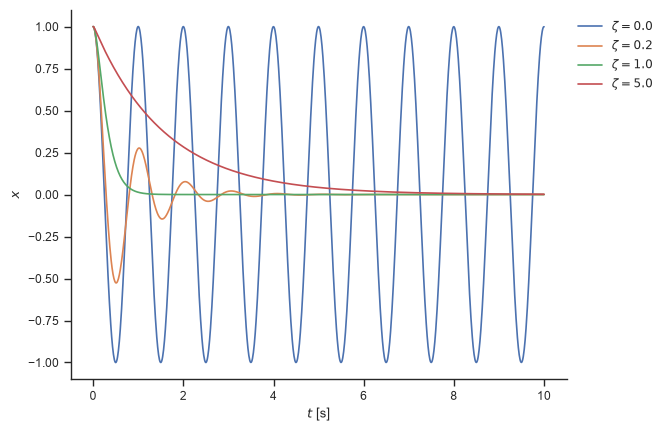

In [33]:
def dy(t, y, ζ, ω0):
    x, p = y[0], y[1]

    dx = p
    dp = -2 * ζ * ω0 * p - ω0**2 * x
    return dx, dp


y0 = [1.0, 0.0]
t = np.linspace(0, 10, 1000)
ω0 = 2 * np.pi * 1.0
from scipy.integrate import solve_ivp

fig, ax = plt.subplots()
for ζ in [0.0, 0.2, 1.0, 5.0]:
    sol = solve_ivp(dy, [0, 10], y0, t_eval=t, args=(ζ, ω0))
    ax.plot(t, sol.y[0], label=rf"$\zeta={ζ}$")
ax.set(xlabel=r"$t$ [s]", ylabel=r"$x$")
ax.legend(bbox_to_anchor=(1, 1));

## **`scpipy.fftpack` : transformations de Fourier**

Afin d'illustrer l'utilisation du module `scipy.fftpack`, on va chercher à déterminer la fréquence du signal issu de l'oscillateur harmonique amorti $\zeta=0.2$ 

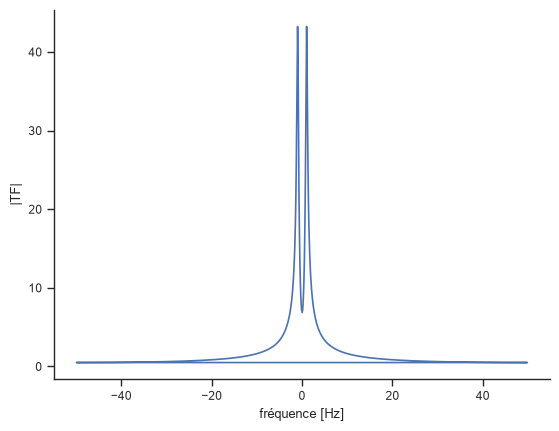

In [42]:
sol = solve_ivp(dy, [0, 10], y0, t_eval=t, args=(0.2, ω0))

from scipy.fftpack import fft, fftfreq

tf = fft(sol.y[0])
freq = fftfreq(t.size, t[1] - t[0])

fig, ax = plt.subplots()
ax.plot(freq, np.abs(tf))
ax.set(xlabel="fréquence [Hz]", ylabel="|TF|");

Seules les fréquences positives sont physiquement pertinentes

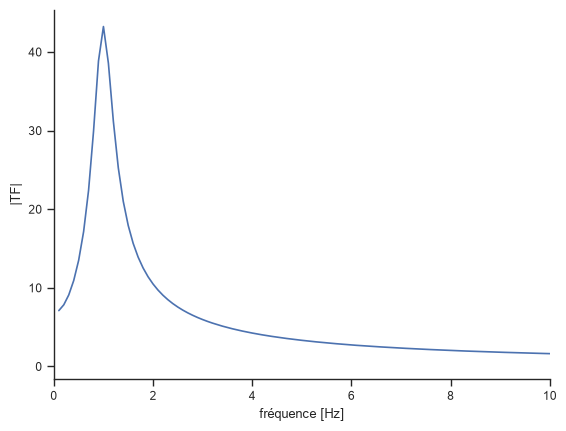

In [45]:
mask = freq > 0

fig, ax = plt.subplots()
ax.plot(freq[mask], np.abs(tf[mask]))
ax.set(xlabel="fréquence [Hz]", ylabel="|TF|", xlim=(0, 10));

On retrouve la fréquence 1 Hz de l'oscillateur harmonique

In [52]:
freq[np.argmax(np.abs(tf))]

np.float64(0.999)

## **`scipy.optimize`**

Le module `scipy.optimize` propose plusieurs algorithmes d'optimisation couramment utilisés. Une liste détaillée est disponible *via* `help(scipy.optimize)`

In [53]:
import scipy.optimize

help(scipy.optimize)

Help on package scipy.optimize in scipy:

NAME
    scipy.optimize

DESCRIPTION
    Optimization and root finding (:mod:`scipy.optimize`)

    .. currentmodule:: scipy.optimize

    .. toctree::
       :hidden:

       optimize.cython_optimize

    SciPy ``optimize`` provides functions for minimizing (or maximizing)
    objective functions, possibly subject to constraints. It includes
    solvers for nonlinear problems (with support for both local and global
    optimization algorithms), linear programming, constrained
    and nonlinear least-squares, root finding, and curve fitting.

    Common functions and objects, shared across different solvers, are:

    .. autosummary::
       :toctree: generated/

       show_options - Show specific options optimization solvers.
       OptimizeResult - The optimization result returned by some optimizers.
       OptimizeWarning - The optimization encountered problems.


    Optimization

    Scalar functions optimization
    ---------------------

### **Recherche des racines d'une fonction**

  \begin{align*}
    f(x_0) = \tan(2\pi x_0) - \frac{1}{x_0} = 0
  \end{align*}

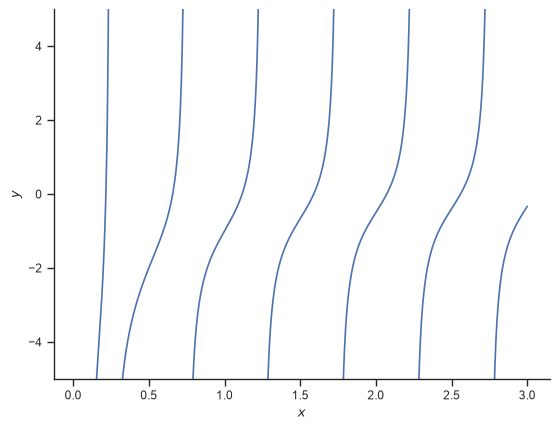

In [64]:
def f(x):
    # This is to avoid the warning message when x = 0
    with np.errstate(divide="ignore"):
        return np.tan(2 * np.pi * x) - 1 / x


x = np.linspace(0, 3, 1000)
y = f(x)
y[np.abs(y) > 50] = np.nan

fig, ax = plt.subplots()
ax.plot(x, y)
ax.set(ylim=(-5, 5), xlabel="$x$", ylabel="$y$");

In [65]:
from scipy.optimize import fsolve

fsolve(f, x0=0.1)

array([0.21612385])

La valeur trouvée par `fsolve` dépend du point initial `x0` de recherche de la racine. On peut cependant donner plusieurs points initiaux de recherche afin de trouver toutes les racines sur l'intervalle recherché

In [67]:
fsolve(f, x0=np.arange(0.1, 3, 0.5))

array([0.21612385, 0.6574377 , 1.116265  , 1.58938086, 2.071577  ,
       2.55928414])

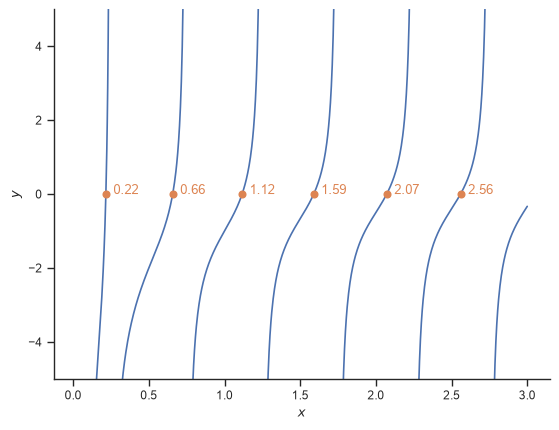

In [82]:
roots = fsolve(f, x0=np.arange(0.1, 3, 0.5))

fig, ax = plt.subplots()
ax.plot(x, y)
ax.set(ylim=(-5, 5), xlabel="$x$", ylabel="$y$")
ax.plot(roots, np.zeros_like(roots), "o")
for root in roots:
    ax.text(root + 0.05, 0.0, f"{root:.2f}", color="C1")

### **Recherche d'*extrema* d'une fonction**

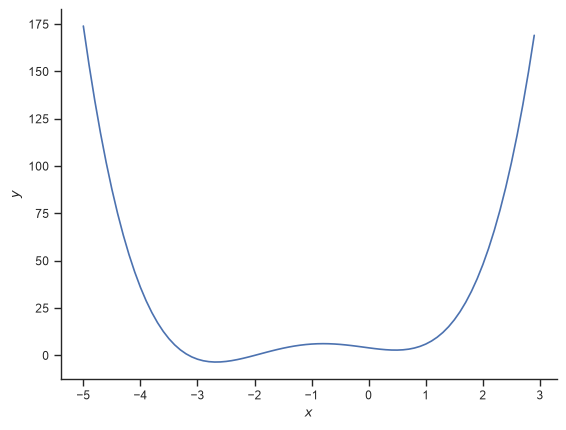

In [122]:
def f(x):
    return 4 * x**3 + (x - 2) ** 2 + x**4

x = np.arange(-5, 3, 0.1)

fig, ax = plt.subplots()
ax.plot(x, f(x))
ax.set(xlabel="$x$", ylabel="$y$");

In [123]:
from scipy.optimize import fmin

xmin = fmin(f, x0=-2)
xmin

Optimization terminated successfully.
         Current function value: -3.506641
         Iterations: 15
         Function evaluations: 30


array([-2.67294922])

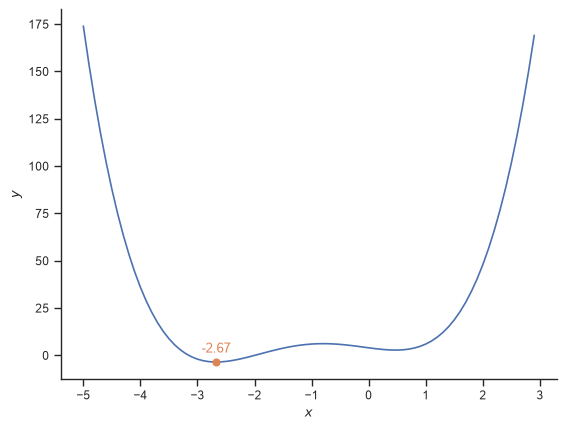

In [124]:
ax.plot(xmin, f(xmin), "o")
ax.text(*xmin, *f(xmin) + 5.0, f"{xmin[0]:.2f}", color="C1", ha="center")
fig

Comme pour la recherche de racines, les *extrema* dépendent de la valeur initiale `x0` 

In [125]:
xmin = fmin(f, x0=0)
xmin

Optimization terminated successfully.
         Current function value: 2.804988
         Iterations: 23
         Function evaluations: 46


array([0.469625])

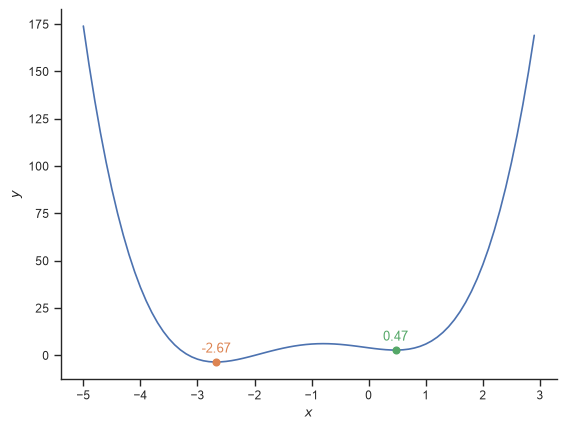

In [126]:
ax.plot(xmin, f(xmin), "o")
ax.text(*xmin, *f(xmin) + 5.0, f"{xmin[0]:.2f}", color="C2", ha="center")
fig

### **Ajustement d'un modèle/fonction à des données**

L'ajustement consiste **à minimiser** une quantité caractérisant le niveau d'accord entre données expérimentales et modèle théorique

*Exemple de fonction à minimiser*

\begin{align*}
      \chi^2(p_0,\ldots,p_n) = \sum_i^N \frac{\left(y_i^\text{data}-y^\text{model}(x_i^\text{data}|p_0,\ldots,p_n)\right)^2}{\sigma_{y_i^\text{data}}^2}
\end{align*}
où $p_0,\ldots,p_n$ sont les $n$ paramètres du modèle.

La fonction `curve_fit` du module `scipy.optimize` prend ainsi comme argument un modèle/fonction dépendant d'un certain nombre de paramètres, les données mesurées sur lesquelles ajuster le modèle ainsi que les incertitudes associées à ces mesures.

Afin d'illustrer l'algorithme et son utilisation, nous allons d'un premier temps générer de "fausses" données (on parle de données simulées) à partir d'un modèle $a\cdot\exp(-b\cdot x) + c$ *i.e.* une exponentielle décroissante avec bruit de fond constant d'amplitude $c$. Dans cet exercice les "vrais" paramètres sont $a=2.5, b=1.3$ et $c=0.5$. Par ailleurs, une incertitude expérimentale $\sigma_y=0.2$ implique que les valeurs de $y$ simulées suivent une distribution normale d'écart-type $\sigma_y$

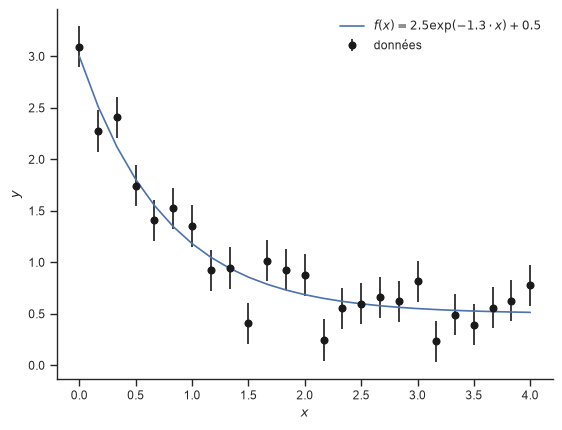

In [144]:
def model(x, a, b, c):
    return a * np.exp(-b * x) + c

# For reproductibility, we fix the seed of the random generator
seed = 1234
np.random.seed(seed)

a, b, c = 2.5, 1.3, 0.5
xsim = np.linspace(0, 4, 25)
σy = 0.2
ysim = model(xsim, a, b, c) + σy * np.random.randn(xsim.size)

fig, ax = plt.subplots()
ax.errorbar(xsim, ysim, yerr=σy, fmt="ok", label="données")
ax.plot(xsim, model(xsim, a, b, c), label=rf"$f(x)={a}\exp(-{b}\cdot x)+{c}$")
ax.set(xlabel="$x$", ylabel="$y$")
ax.legend();

In [145]:
from scipy.optimize import curve_fit

popt, pcov = curve_fit(model, xsim, ysim, sigma=np.full_like(ysim, σy))

La fonction `curve_fit` retourne 2 paramètres : `popt` correspond aux valeurs des paramètres du modèle optimisées, `pcov` correspond à la matrice de covariance des paramètres du modèle.

In [146]:
popt

array([2.5161928 , 1.34857552, 0.52071692])

Par rapport à ces paramètres optimisés, on peut d'une part, représenter graphiquement ce modèle optimisé, d'autre part calculer la valeur de $\chi^2$ et le comparer au nombre de degrés de liberté *i.e.* le nombre de données expérimentales moins le nombre de paramètres du modèle.

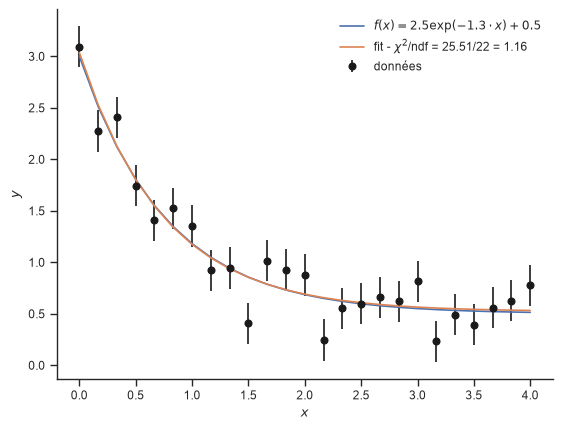

In [147]:
chi2 = np.sum((ysim - model(xsim, *popt)) ** 2 / σy**2)
ndof = xsim.size - 3
chi2_reduced = chi2 / ndof

ax.plot(
    xsim,
    model(xsim, *popt),
    label=rf"fit - $\chi^2$/ndf = {chi2:.2f}/{ndof} = {chi2_reduced:.2f}",
)
ax.legend()
fig

Les valeurs optimisées des paramètres sont à comparer aux valeurs théoriques $a=2.5, b=1.3$ et $c=0.5$. Toutefois, cette comparaison ne peut se faire qu'au regard des incertitudes associées à ces paramètres, elles-mêmes directement reliées aux incertitudes $\sigma_y$ expérimentales. Les incertitudes (statistiques) peuvent être extraites de la matrice de covariance `pcov`. Pour rappel, la matrice de covariance a pour expression

\begin{align*}
\text{Cov}(p_0,\cdots,p_n)=\left(
\begin{array}{cccc}
  \sigma_{p_0}^2&\sigma_{p_0p_1}&\cdots&\sigma_{p_0p_n}\\
  \sigma_{p_1p_0}&\sigma_{p_1}^2&\cdots&\sigma_{p_1p_n}\\
  \vdots&\vdots&\ddots&\vdots\\
  \sigma_{p_np_0}&\cdots&\cdots&\sigma_{p_n}^2
\end{array}
\right)\\
\text{avec }\sigma_{p_ip_j}=\langle p_i\rangle\langle p_j\rangle - \langle p_ip_j\rangle
\end{align*}

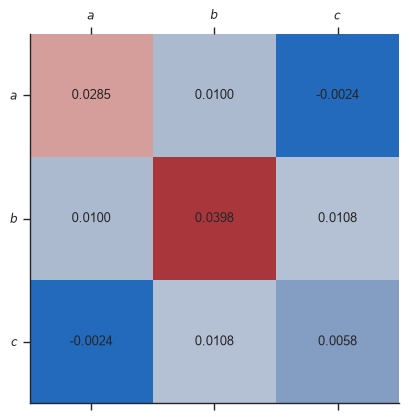

In [148]:
from itertools import product

fig, ax = plt.subplots()
ms = ax.matshow(pcov, cmap=sns.color_palette("vlag", as_cmap=True))
ax.set(
    xticks=(ticks := [0, 1, 2]),
    xticklabels=(label := ["$a$", "$b$", "$c$"]),
    yticks=ticks,
    yticklabels=label,
)
for i, j in product(ticks, ticks):
    ax.text(i, j, f"{pcov[i, j]:.4f}", va="center", ha="center")

Ainsi, les incertitudes statistiques associées à chaque paramètre $a,b,c$ sont

In [149]:
np.sqrt(np.diag(pcov))

array([0.16892685, 0.1995881 , 0.07633932])

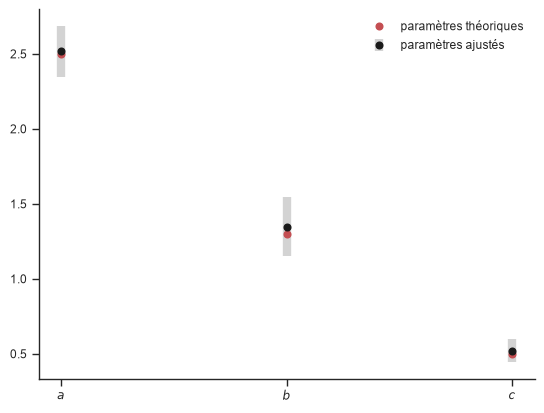

In [159]:
fig, ax = plt.subplots()

ax.errorbar(
    ticks,
    popt,
    yerr=np.sqrt(np.diag(pcov)),
    fmt="ok",
    label="paramètres ajustés",
    ecolor="lightgray",
    elinewidth=6,
)
ax.plot(ticks := [0, 1, 2], [a, b, c], "or", label="paramètres théoriques")
ax.set(xticks=ticks, xticklabels=["$a$", "$b$", "$c$"])
ax.legend();

Aux incertitudes près (ici représentées par les barres d'erreur grises), les paramètres reconstruits sont ainsi statistiquement compatibles avec les valeurs théoriques. 

Une dernière information extraite de la matrice de covariance est la corrélation entre paramètres $a,b,c$ et correspond aux termes hors diagonal dans la matrice de covariance

\begin{align*}
R_{ij}&=\frac{\text{Cov}_{ij}}{\surd{\text{Cov}_{ii}\text{Cov}_{jj}}}\\
\end{align*}
\begin{align*}
R_{ij}=\left(
\begin{array}{cccc}
  1&\frac{\sigma_{p_0p_1}}{\sigma_{p_0}\sigma_{p_1}}&\cdots&\frac{\sigma_{p_0p_n}}{\sigma_{p_0}\sigma_{p_n}}\\
  \frac{\sigma_{p_1p_0}}{\sigma_{p_1}\sigma_{p_0}}&1&\cdots&\frac{\sigma_{p_1p_n}}{\sigma_{p_1}\sigma_{p_n}}\\
  \vdots&\vdots&\ddots&\vdots\\
  \frac{\sigma_{p_np_0}}{\sigma_{p_n}\sigma_{p_0}}&\cdots&\cdots&1
\end{array}
\right)
\end{align*}

La valeur du coefficient de corrélation indique la (anti-)corrélation entre paramètres du modèle 

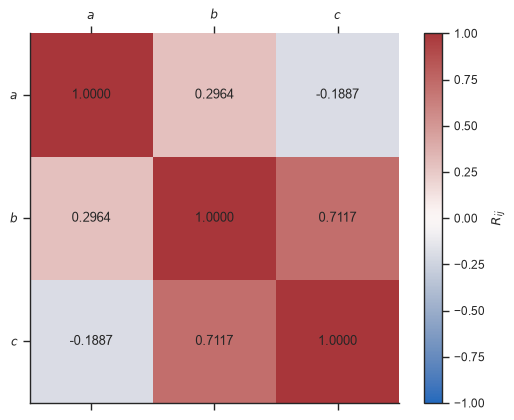

In [164]:
d = np.sqrt(np.diag(pcov))
corr = (pcov / d).T / d

fig, ax = plt.subplots()
ms = ax.matshow(corr, cmap=sns.color_palette("vlag", as_cmap=True), vmin=-1, vmax=1)
ax.set(
    xticks=(ticks := [0, 1, 2]),
    xticklabels=(label := ["$a$", "$b$", "$c$"]),
    yticks=ticks,
    yticklabels=label,
)
for i, j in product(ticks, ticks):
    ax.text(i, j, f"{corr[i, j]:.4f}", va="center", ha="center")
cb = fig.colorbar(ms)
cb.set_label("$R_{ij}$")

## **`scipy.stats` : distribution & tests statistiques**

L'adéquation d'un modèle avec des données peut être quantifié par la valeur du $\chi^2$ relativement au nombre de degrés de liberté. Statistiquement, la $\chi^2$ suit une loi de distribution qui dépend du nombre de degrés de liberté

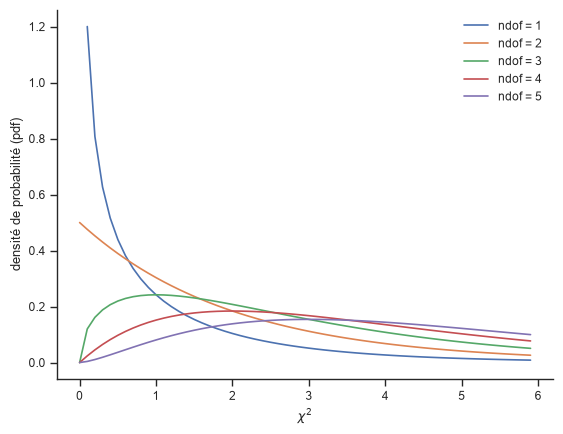

In [176]:
from scipy import stats

fig, ax = plt.subplots()
for ndof in [1, 2, 3, 4, 5]:
    ax.plot(chi2 := np.arange(0, 6, 0.1), stats.chi2(ndof).pdf(chi2), label=f"ndof = {ndof}")
ax.set(xlabel="$\chi^2$", ylabel="densité de probabilité (pdf)")
ax.legend();

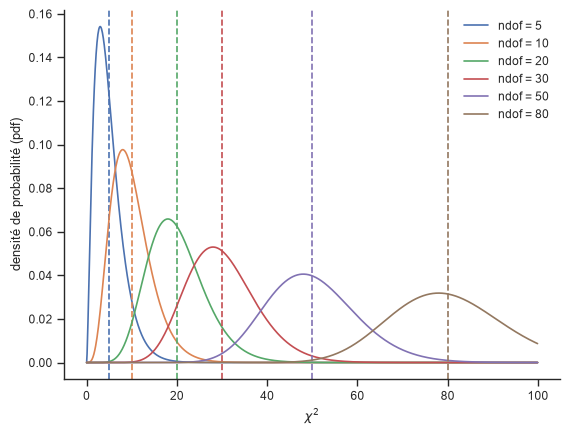

In [177]:
fig, ax = plt.subplots()
for i, ndof in enumerate(ndofs := [5, 10, 20, 30, 50, 80]):
    ax.plot(chi2 := np.arange(0, 100, 0.1), stats.chi2(ndof).pdf(chi2), label=f"ndof = {ndof}")
    ax.axvline(ndof, ls="--", color=f"C{i}")
ax.set(xlabel="$\chi^2$", ylabel="densité de probabilité (pdf)")
ax.legend();

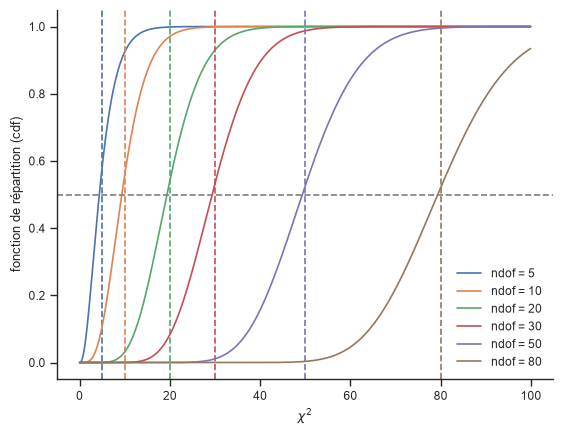

In [179]:
fig, ax = plt.subplots()
for i, ndof in enumerate(ndofs):
    ax.plot(chi2, stats.chi2(ndof).cdf(chi2), label=f"ndof = {ndof}")
    ax.axvline(ndof, ls="--", color=f"C{i}")
ax.axhline(0.5, ls="--", color="gray")
ax.set(xlabel="$\chi^2$", ylabel="fonction de répartition (cdf)")
ax.legend();

À l'aide du module `scipy.stats`, on peut également comparer statistiquement la compatibilité entre 2 distributions

In [183]:
t_statistic, p_value = stats.ttest_ind(stats.norm().rvs(1000), stats.norm().rvs(1000))
t_statistic, p_value

(np.float64(1.1107566456986595), np.float64(0.2668067641004019))